# 01 — Data Quality & Exploratory Data Analysis

**RetailPulse 360 — Customer Growth, Churn & Segmentation Analytics**

> **Synthetic data disclosure.** RetailPulse 360 is a fictional company. Every table and the churn target are synthetic, created for an AI-assisted learning and portfolio project. Nothing here describes real customers or real business results.

**Business questions in this notebook**
1. Can the data be trusted? What are its quirks, and how should each KPI be defined?
2. How are revenue, profit, orders, customers and AOV trending?
3. Which categories, regions and channels matter most?
4. How efficient is marketing, and how do refunds, support and conversion behave?
5. How well are customers retained?

Each section follows the same pattern: **question → method → result → business implication**. All reusable logic lives in `src/retailpulse360/` and is covered by `tests/`.

## 1. Setup and data loading

In [1]:
import sys
from pathlib import Path

# Make the project package importable whether the notebook runs from notebooks/ or the repo root.
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from retailpulse360 import SYNTHETIC_DISCLAIMER, data, features, metrics, pipeline, plotting, quality

plotting.apply_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
%matplotlib inline

In [2]:
tables = data.load_raw_tables()
snapshot = data.load_snapshot()
for name, df in tables.items():
    print(f"{name:<16} {df.shape[0]:>7,} rows x {df.shape[1]:>2} columns")
print(f"{'snapshot':<16} {snapshot.shape[0]:>7,} rows x {snapshot.shape[1]:>2} columns")

customers          6,000 rows x  7 columns
products             120 rows x  5 columns
orders            30,054 rows x 15 columns
order_items       56,183 rows x  8 columns
web_sessions      76,327 rows x 11 columns
support_tickets    4,662 rows x  8 columns
marketing_spend      174 rows x  6 columns
snapshot           6,000 rows x 27 columns


Date columns are parsed when the data loads. Text columns stay as strings and numeric columns as numbers. The raw files are only read, never written.

In [3]:
tables["orders"].dtypes.to_frame("dtype").T

,order_id,customer_id,order_date,sales_channel,payment_method,shipping_type,coupon_used,discount_pct,order_status,shipping_fee_usd,tax_amount_usd,gross_merchandise_value_usd,net_revenue_usd,total_cost_usd,profit_usd
dtype,str,str,datetime64[us],str,str,str,int64,float64,str,float64,float64,float64,float64,float64,float64


## 2. Data-quality checks

**Method.** Reusable checks from `quality.py`: table overview (missing and duplicate rows), primary-key uniqueness, foreign-key integrity, financial reconciliation between orders and line items, business rules and extreme values.

Repeated foreign keys, such as a customer with many orders or a month listed for six channels, are expected. Duplicates are tested only on primary keys and on whole rows.

In [4]:
overview = quality.table_overview(tables)
overview

,table,rows,columns,missing_cells,duplicate_rows,date_range
0,customers,6000,7,0,0,2023-01-01 to 2026-05-15
1,products,120,5,0,0,
2,orders,30054,15,0,0,2024-01-01 to 2026-05-31
3,order_items,56183,8,0,0,
4,web_sessions,76327,11,0,0,2024-01-01 to 2026-05-31
5,support_tickets,4662,8,0,0,2024-01-01 to 2026-05-31
6,marketing_spend,174,6,0,0,2024-01-01 to 2026-05-01


In [5]:
display(quality.check_primary_keys(tables))
display(quality.check_foreign_keys(tables))

,table,key,null_keys,duplicate_keys,passed
0,customers,customer_id,0,0,True
1,products,product_id,0,0,True
2,orders,order_id,0,0,True
3,order_items,order_item_id,0,0,True
4,web_sessions,session_id,0,0,True
5,support_tickets,ticket_id,0,0,True
6,marketing_spend,month + channel,0,0,True


,relationship,orphan_rows,passed
0,orders.customer_id -> customers.customer_id,0,True
1,order_items.order_id -> orders.order_id,0,True
2,order_items.product_id -> products.product_id,0,True
3,web_sessions.customer_id -> customers.customer_id,0,True
4,support_tickets.customer_id -> customers.custo...,0,True


**How order status affects the money columns.** Line items are first aggregated to order grain, so the join to orders is one-to-one and nothing is fanned out. Each rule below is then tested.

In [6]:
quality.reconcile_order_financials(tables["orders"], tables["order_items"])

,scope,rule,orders_checked,violations
0,All,GMV = sum of line revenue (post-discount),30054,0
1,All,Profit = net revenue - total cost,30054,0
2,All,Order discount = every line discount,30054,0
3,Completed,Net revenue = GMV + shipping fee (tax excluded),28436,0
4,Completed,Total cost = sum of line cost,28436,0
5,Refunded,Net revenue = 0,1253,0
6,Refunded,Total cost = sum of line cost (goods not recov...,1253,0
7,Cancelled,"Net revenue, cost and profit = 0",365,0


Every rule holds with zero violations, which gives us defensible KPI definitions:

| Status | Net revenue | Cost | Profit |
|---|---|---|---|
| Completed | GMV + shipping fee (tax excluded) | merchandise cost | revenue − cost |
| Refunded | 0 | merchandise cost (goods not recovered) | **negative** (a loss) |
| Cancelled | 0 | 0 | 0 |

The resulting definitions:
- **GMV** counts every placed order, so it measures demand, not earned revenue.
- **AOV** = net revenue ÷ *completed* orders. Dividing by all orders would understate it.
- **Refund rate** = refunded ÷ (completed + refunded), the share of fulfilled orders that were refunded.

In [7]:
rules = quality.business_rule_checks(tables)
rules[rules["rows_flagged"] > 0]

,table,check,rows_flagged
7,orders,coupon_used = 1 but discount_pct = 0,4079
9,orders,Completed order with negative profit,2


Only two checks flag rows:
- **4,079 orders have `coupon_used = 1` with a 0% discount.** These may be free-shipping or fixed-amount coupons. There is no coupon-type field to confirm, so discount analysis uses `discount_pct`.
- **2 completed orders have negative profit.** Both carry a 25% discount that pushed the price below unit cost. They are valid transactions, and a small example of the margin risk of deep discounts.

In [8]:
quality.outlier_summary(tables)

,table,column,lower_fence,upper_fence,outliers,max
0,orders,gross_merchandise_value_usd,-309.95,527.51,239,"1,049.88"
1,orders,profit_usd,-116.56,205.63,588,398.53
2,order_items,unit_price_usd,-81.11,178.62,918,246.38
3,web_sessions,session_minutes,-20.34,37.28,372,60.00
4,web_sessions,pages_viewed,-8.00,20.00,1,21.00
5,support_tickets,resolution_hours,-48.73,84.76,45,138.17
6,marketing_spend,spend_usd,"-63,475.54","111,940.29",0,"55,591.81"


Extreme values (beyond 3 × IQR) are counted but kept. Large baskets, long sessions and slow tickets are all plausible for a retailer, and removing them would bias revenue.

### Modeling-snapshot audit

The provided snapshot is rebuilt from raw data using only events on or before 2026-05-31. If the rebuilt features match, the snapshot features cannot contain future information.

In [9]:
rebuilt = features.build_customer_features(tables)
reproduction = quality.snapshot_reproduction_check(snapshot, rebuilt, features.SNAPSHOT_NUMERIC_FEATURES)
print(f"Features rebuilt: {len(reproduction)}; minimum match rate: {reproduction['match_rate'].min():.1%}")
reproduction.head()

Features rebuilt: 20; minimum match rate: 100.0%


,feature,match_rate,mismatches
0,days_since_signup,1.00,0
1,recency_days,1.00,0
2,frequency_12m,1.00,0
3,monetary_value_12m,1.00,0
4,avg_order_value_12m,1.00,0


In [10]:
frame = features.add_corrected_features(snapshot, tables["orders"])
no_recent = frame[frame["no_purchase_12m"] == 1]
print(f"Customers without a completed order in the 12-month window: {len(no_recent):,}")
print(f"  recency_days == days_since_signup + 30 for all of them: {(no_recent['recency_days'] == no_recent['days_since_signup'] + 30).all()}")
print(f"  ...of whom bought earlier (true recency differs): {(no_recent['never_purchased'] == 0).sum():,}")
print(f"  ...and never purchased at all: {no_recent['never_purchased'].sum():,}")
print(f"Customers without tickets whose avg_csat_12m is imputed as 4.0: {(frame['support_tickets_12m'] == 0).sum():,}")

Customers without a completed order in the 12-month window: 606
  recency_days == days_since_signup + 30 for all of them: True
  ...of whom bought earlier (true recency differs): 289
  ...and never purchased at all: 317
Customers without tickets whose avg_csat_12m is imputed as 4.0: 3,702


**Findings.**
- All 20 numeric snapshot features match the raw data exactly, so there is **no leakage from after the snapshot date** in the features.
- `recency_days` is a **sentinel** (`days_since_signup + 30`) for customers with no purchase in the last 12 months, even for customers who did buy earlier. Models in Notebook 02 replace it with true recency (`days_since_last_purchase`) and explicit flags.
- `avg_csat_12m = 4.0` is an imputed value for customers without tickets. `support_tickets_12m = 0` identifies these rows.

The full audit is written to `reports/data_quality_report.md` by `scripts/run_pipeline.py`.

## 3. KPI overview

**Question.** What does the business look like over the whole observed period (January 2024 – May 2026)?

In [11]:
business = pipeline.business_tables(tables)
summary = business["executive_summary"]
pd.Series(summary).to_frame("value")

,value
period_start,2024-01-01
period_end,2026-05-31
customers,6000
purchasing_customers,5683
orders_placed,30054
completed_orders,28436
refunded_orders,1253
cancelled_orders,365
gmv_usd,"3,786,080.27"
net_revenue_usd,"3,643,299.56"


In [12]:
display(Markdown(
    f"Net revenue was **${summary['net_revenue_usd']:,.0f}** from **{summary['completed_orders']:,}** completed orders "
    f"(AOV **${summary['aov_usd']:,.2f}**). Product-level profit was **${summary['profit_usd']:,.0f}** "
    f"(**{summary['profit_margin_pct']:.1f}%** margin) after **${summary['refund_loss_usd']:,.0f}** of refund losses. "
    f"GMV (**${summary['gmv_usd']:,.0f}**) differs from net revenue in two ways: it includes refunded and cancelled orders "
    f"(adding value) and excludes shipping fees (removing value)."
))

Net revenue was **$3,643,300** from **28,436** completed orders (AOV **$128.12**). Product-level profit was **$1,422,054** (**39.0%** margin) after **$95,059** of refund losses. GMV (**$3,786,080**) differs from net revenue in two ways: it includes refunded and cancelled orders (adding value) and excludes shipping fees (removing value).

## 4. Monthly trends

**Method.** KPIs are computed per calendar month. Every month from January 2024 to May 2026 is complete (May 2026 has data for all 31 days), so month-over-month comparisons are valid. For year-over-year, 2026 has only five months, so the comparison uses **January–May of each year**.

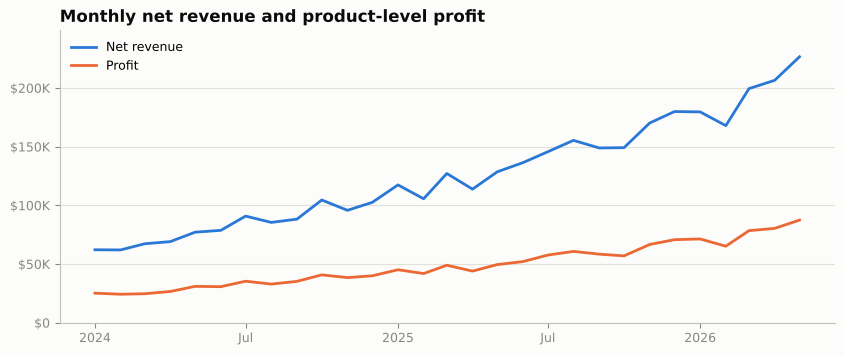

In [13]:
monthly = business["monthly_kpis"]
fig, ax = plt.subplots(figsize=(10, 3.8))
plotting.line_chart(monthly, "order_month", "net_revenue_usd", "Monthly net revenue and product-level profit", ax=ax, label="Net revenue")
ax.plot(monthly["order_month"], monthly["profit_usd"], color=plotting.PALETTE[1], label="Profit")
plotting.money(ax)
ax.legend(loc="upper left")
plt.show()

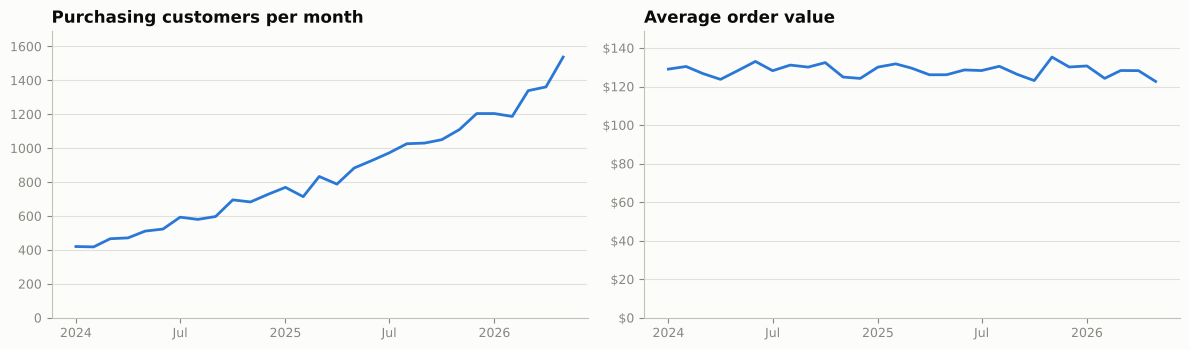

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
plotting.line_chart(monthly, "order_month", "active_customers", "Purchasing customers per month", ax=ax1)
plotting.line_chart(monthly, "order_month", "aov_usd", "Average order value", ax=ax2)
plotting.money(ax2)
fig.tight_layout()
plt.show()

In [15]:
monthly[["order_month", "net_revenue_usd", "profit_usd", "completed_orders", "active_customers", "aov_usd", "revenue_mom_pct", "revenue_yoy_pct"]].tail(6)

,order_month,net_revenue_usd,profit_usd,completed_orders,active_customers,aov_usd,revenue_mom_pct,revenue_yoy_pct
23,2025-12-01,"179,955.72","70,794.00",1383,1204,130.12,5.75,75.41
24,2026-01-01,"179,666.43","71,402.90",1375,1204,130.67,-0.16,52.96
25,2026-02-01,"167,957.18","65,232.13",1352,1187,124.23,-6.52,58.95
26,2026-03-01,"199,506.69","78,490.44",1555,1339,128.30,18.78,56.87
27,2026-04-01,"206,576.84","80,424.59",1611,1361,128.23,3.54,81.43
28,2026-05-01,"226,629.20","87,489.83",1848,1537,122.63,9.71,76.18


In [16]:
ytd = business["yearly_kpis_jan_may"]
ytd[["year", "net_revenue_usd", "profit_usd", "completed_orders", "active_customers", "aov_usd", "profit_margin_pct", "refund_rate_pct"]]

,year,net_revenue_usd,profit_usd,completed_orders,active_customers,aov_usd,profit_margin_pct,refund_rate_pct
0,2024,"337,895.76","131,966.45",2650,1495,127.51,39.06,4.33
1,2025,"592,791.90","229,736.80",4610,2611,128.59,38.76,4.46
2,2026,"980,336.34","383,039.89",7741,4166,126.64,39.07,4.06


In [17]:
y = ytd.set_index("year")
display(Markdown(
    f"January–May 2026 net revenue is **{100 * (y.loc[2026, 'net_revenue_usd'] / y.loc[2025, 'net_revenue_usd'] - 1):.1f}%** above January–May 2025. "
    f"Purchasing customers rose **{100 * (y.loc[2026, 'active_customers'] / y.loc[2025, 'active_customers'] - 1):.1f}%**, "
    f"while AOV changed by only **{100 * (y.loc[2026, 'aov_usd'] / y.loc[2025, 'aov_usd'] - 1):.1f}%**. "
    f"Revenue fell month-over-month in **{(monthly['revenue_mom_pct'] < 0).sum()}** of {monthly['revenue_mom_pct'].notna().sum()} month-to-month comparisons."
))

January–May 2026 net revenue is **65.4%** above January–May 2025. Purchasing customers rose **59.6%**, while AOV changed by only **-1.5%**. Revenue fell month-over-month in **8** of 28 month-to-month comparisons.

**Implication.** Growth comes from **more buyers and more orders, not bigger baskets**. AOV and margin are almost flat, so growth depends on acquiring and retaining customers, which is why marketing efficiency and retention get a closer look below.

## 5. Product categories

**Method.** Category results are computed at line-item grain. Each line takes its order's status through a many-to-one join (no fan-out). Category revenue excludes shipping fees, so the categories sum to net revenue minus shipping.

In [18]:
category = business["category_performance"]
category[["category", "products", "units_sold", "revenue_usd", "profit_usd", "gross_margin_pct", "revenue_share_pct", "profit_share_pct", "line_refund_rate_pct"]]

,category,products,units_sold,revenue_usd,profit_usd,gross_margin_pct,revenue_share_pct,profit_share_pct,line_refund_rate_pct
0,Office,25,13557,"876,785.20","342,607.02",39.08,24.49,25.20,4.06
1,Beauty,21,11276,"707,820.19","254,126.78",35.90,19.77,18.69,4.33
2,Sports & Outdoors,23,12249,"539,412.65","205,441.68",38.09,15.06,15.11,4.37
3,Apparel,17,9034,"511,372.81","201,609.33",39.43,14.28,14.83,4.06
4,Home & Kitchen,16,8482,"473,097.81","165,681.10",35.02,13.21,12.19,4.10
5,Electronics,18,9718,"472,376.32","190,153.83",40.25,13.19,13.99,4.31


Category revenue + shipping = $3,643,299.56; total net revenue = $3,643,299.56


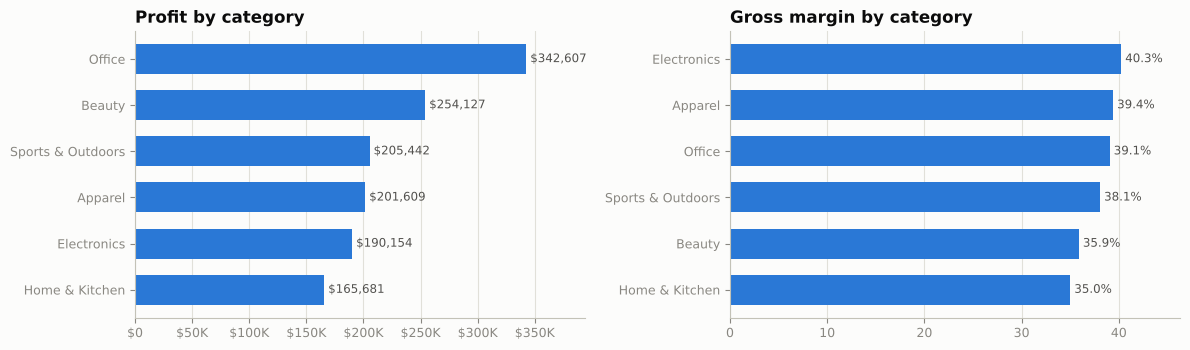

In [19]:
shipping = tables["orders"].query("order_status == 'Completed'")["shipping_fee_usd"].sum()
print(f"Category revenue + shipping = ${category['revenue_usd'].sum() + shipping:,.2f}; total net revenue = ${summary['net_revenue_usd']:,.2f}")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
plotting.barh_chart(category, "category", "profit_usd", "Profit by category", fmt="${:,.0f}", ax=ax1)
plotting.money(ax1, axis="x")
plotting.barh_chart(category, "category", "gross_margin_pct", "Gross margin by category", fmt="{:.1f}%", ax=ax2)
fig.tight_layout()
plt.show()

**Result.** Office is the largest category by revenue and profit. Electronics has the highest margin, while Home & Kitchen and Beauty have the lowest. Line-level refund rates fall in a narrow band (about 4.1–4.4%) across categories, so refunds are not concentrated in one category.

**Implication.** Margin differences across categories (about 5 percentage points) matter more than refund differences. Category mix and pricing in Beauty and Home & Kitchen are worth reviewing.

## 6. Regions, acquisition channels and sales channels

In [20]:
business["region_performance"][["region", "customers", "purchasing_customers", "net_revenue_usd", "profit_usd", "aov_usd", "revenue_per_customer_usd", "refund_rate_pct", "revenue_share_pct"]]

,region,customers,purchasing_customers,net_revenue_usd,profit_usd,aov_usd,revenue_per_customer_usd,refund_rate_pct,revenue_share_pct
0,South,1870,1767,"1,155,165.65","448,325.51",128.75,617.74,4.20,31.71
1,West,1653,1581,"993,788.44","390,721.22",126.97,601.20,4.32,27.28
2,Midwest,1304,1224,"780,733.26","303,990.45",127.40,598.72,4.55,21.43
3,Northeast,1173,1111,"713,612.21","279,017.14",129.54,608.37,3.76,19.59


In [21]:
business["acquisition_channel_performance"][["acquisition_channel", "customers", "net_revenue_usd", "profit_usd", "aov_usd", "revenue_per_customer_usd", "refund_rate_pct"]]

,acquisition_channel,customers,net_revenue_usd,profit_usd,aov_usd,revenue_per_customer_usd,refund_rate_pct
0,Organic Search,1501,"926,310.70","360,219.31",127.42,617.13,4.37
1,Paid Search,1173,"726,993.17","284,074.24",126.39,619.77,4.47
2,Paid Social,991,"626,569.45","243,802.65",130.35,632.26,4.13
3,Referral,958,"555,103.50","215,779.07",127.90,579.44,4.15
4,Email,758,"429,227.47","169,885.74",128.97,566.26,3.70
5,Affiliate,619,"379,095.27","148,293.31",128.99,612.43,4.20


In [22]:
business["sales_channel_performance"][["sales_channel", "completed_orders", "net_revenue_usd", "aov_usd", "profit_margin_pct", "refund_rate_pct", "revenue_share_pct"]]

,sales_channel,completed_orders,net_revenue_usd,aov_usd,profit_margin_pct,refund_rate_pct,revenue_share_pct
0,Website,15708,"2,012,072.05",128.09,39.03,4.23,55.23
1,Mobile App,9955,"1,274,284.73",128.00,39.14,3.98,34.98
2,Marketplace,2773,"356,942.78",128.72,38.67,5.00,9.80


**Result.** Regions differ mainly in **size**: the South has the most customers. Revenue per customer and AOV are very similar across regions, so no region under-performs per customer. The Website brings in more than half of revenue. Acquisition channels differ in lifetime revenue per customer, but those totals depend on *when* customers signed up. A fair comparison needs an equal time window:

In [23]:
business["first_year_value_by_channel"]

,acquisition_channel,cohort_customers,first_year_revenue_per_customer_usd,first_year_profit_per_customer_usd,share_with_purchase_pct
0,Paid Social,387,382.09,145.88,92.25
1,Affiliate,266,362.94,144.55,90.23
2,Organic Search,653,368.65,143.86,91.88
3,Paid Search,459,352.60,138.03,91.50
4,Email,336,348.15,136.21,88.39
5,Referral,414,337.87,128.29,89.37


Measured over each customer's first 365 days, the channels deliver similar first-year profit per customer. Customer quality is broadly the same whichever channel brought them in. This matters for the marketing analysis.

*Caution: synthetic data tends to be more uniform than reality. "No difference" here should not be read as a real-world finding.*

## 7. Marketing efficiency

**Method.** Marketing data is at month × channel grain with no customer key, so it is **never joined row-by-row to orders** (that would duplicate spend). Channel totals give CTR, CPC and cost per lead. Spend per new customer divides channel spend by sign-ups attributed to that channel in the same period. This relies on attribution and is not an incrementality measure.

In [24]:
business["marketing_efficiency"][["acquisition_channel", "spend_usd", "spend_share_pct", "ctr_pct", "cpc_usd", "cost_per_lead_usd", "new_customers", "spend_per_new_customer_usd"]]

,acquisition_channel,spend_usd,spend_share_pct,ctr_pct,cpc_usd,cost_per_lead_usd,new_customers,spend_per_new_customer_usd
0,Paid Search,"1,261,833.08",31.80,3.50,2.23,26.11,798,"1,581.24"
1,Paid Social,"1,114,145.92",28.08,2.56,1.56,19.50,667,"1,670.38"
2,Affiliate,"527,682.07",13.30,2.98,1.05,12.96,440,"1,199.28"
3,Referral,"427,612.87",10.78,2.50,0.83,10.81,671,637.28
4,Organic Search,"360,650.11",9.09,2.69,0.34,3.90,1067,338.00
5,Email,"275,812.20",6.95,2.98,0.22,2.73,569,484.73


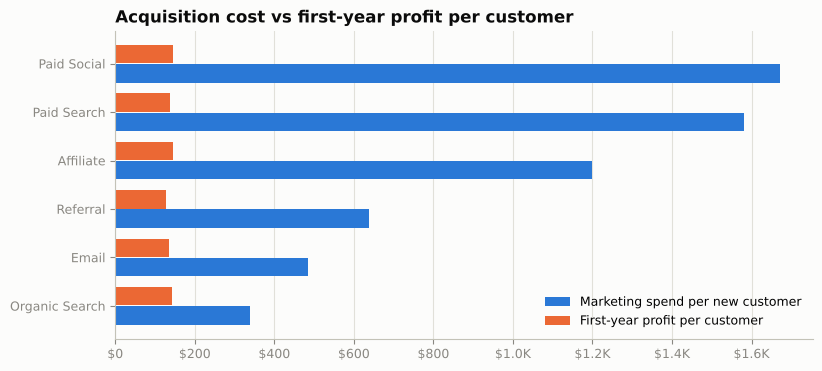

,acquisition_channel,spend_per_new_customer_usd,first_year_profit_per_customer_usd,spend_to_first_year_profit_ratio
0,Paid Social,"1,670.38",145.88,11.45
1,Paid Search,"1,581.24",138.03,11.46
2,Affiliate,"1,199.28",144.55,8.30
3,Referral,637.28,128.29,4.97
4,Email,484.73,136.21,3.56
5,Organic Search,338.00,143.86,2.35


In [25]:
ue = business["unit_economics_by_channel"]
fig, ax = plt.subplots(figsize=(9, 4))
ypos = np.arange(len(ue))
ax.barh(ypos + 0.2, ue["spend_per_new_customer_usd"], height=0.38, color=plotting.PALETTE[0], label="Marketing spend per new customer")
ax.barh(ypos - 0.2, ue["first_year_profit_per_customer_usd"], height=0.38, color=plotting.PALETTE[1], label="First-year profit per customer")
ax.set_yticks(ypos, ue["acquisition_channel"])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
plotting.money(ax, axis="x")
ax.set_title("Acquisition cost vs first-year profit per customer")
ax.legend(loc="lower right")
plt.show()
ue[["acquisition_channel", "spend_per_new_customer_usd", "first_year_profit_per_customer_usd", "spend_to_first_year_profit_ratio"]]

In [26]:
business["marketing_vs_profit_by_year"]

,year,net_revenue_usd,profit_usd,marketing_spend_usd,profit_after_marketing_usd,marketing_pct_of_revenue
0,2024,"984,338.70","385,705.11","1,663,635.42","-1,277,930.31",169.01
1,2025,"1,678,624.52","653,309.32","1,639,442.46","-986,133.14",97.67
2,2026,"980,336.34","383,039.89","664,658.37","-281,618.48",67.80


**Result.** This is the most important finding in the EDA.
- Total recorded marketing spend is larger than total product-level profit for every year shown, although the gap is narrowing as revenue grows faster than spend.
- Paid Social and Paid Search cost roughly 11× a new customer's first-year profit. Organic Search and Email cost about 2–4×.

**Implication.** Paid acquisition does not pay back within a year at current costs, and customer quality (first-year profit) is similar across channels. Testing budget reallocation with **holdout experiments** is the highest-value next step. The analysis cannot prove what would happen if spend were cut, because attribution is single-touch and no experiment data exists.

## 8. Conversion funnel

In [27]:
display(business["funnel_overall"])
display(business["funnel_by_device"][["device", "sessions", "conversion_rate_pct", "cart_rate_pct", "checkout_completion_pct"]])
display(business["funnel_by_traffic_source"][["traffic_source", "sessions", "conversion_rate_pct", "checkout_completion_pct"]])

,segment,sessions,viewed_product,added_to_cart,checkout_started,converted,avg_session_minutes,conversion_rate_pct,cart_rate_pct,checkout_completion_pct
0,All sessions,76327,70625,40797,22495,13504,9.39,17.69,53.45,60.03


,device,sessions,conversion_rate_pct,cart_rate_pct,checkout_completion_pct
0,Mobile,47202,17.68,53.56,59.85
1,Desktop,24499,17.57,53.21,60.05
2,Tablet,4626,18.50,53.55,61.76


,traffic_source,sessions,conversion_rate_pct,checkout_completion_pct
0,Organic Search,22001,17.72,60.28
1,Paid Search,13636,17.57,60.35
2,Paid Social,13011,17.58,59.10
3,Email,10676,18.23,61.12
4,Referral,9252,17.40,59.56
5,Affiliate,7751,17.62,59.39


**Result.** About 18% of sessions convert, and roughly 60% of started checkouts complete. Conversion is almost identical across devices and traffic sources (within about 1 percentage point), which is typical of synthetic data. The biggest drop-off is between *added to cart* and *checkout started*.

**Limitation.** Sessions cannot be linked to orders (orders have no `session_id`), so session conversion cannot be reconciled with order counts.

## 9. Refunds and discounts

In [28]:
business["discount_band_performance"][["discount_band", "completed_orders", "aov_usd", "profit_margin_pct", "refund_rate_pct"]]

,discount_band,completed_orders,aov_usd,profit_margin_pct,refund_rate_pct
0,0%,21955,131.96,40.77,4.13
1,1-10%,3474,119.52,35.92,4.56
2,11-15%,1462,113.80,30.59,4.76
3,16-20%,1040,110.61,26.02,4.59
4,21%+,505,97.92,22.23,3.63


In [29]:
stats = pipeline.statistical_checks(tables, frame)
pd.DataFrame(stats).T[["rate_a_pct", "rate_b_pct", "difference_pp", "p_value"]]

,rate_a_pct,rate_b_pct,difference_pp,p_value
refund_rate_marketplace_vs_website,5.00,4.23,0.77,0.07
refund_rate_discounted_vs_full_price,4.54,4.13,0.41,0.15
churn_rate_bronze_vs_platinum,30.65,15.92,14.73,0.00


**Result.**
- Margin falls steadily as discounts deepen (from about 41% at full price to about 22% at 21%+).
- Discounted orders are **not** refunded significantly more often (p ≈ 0.15).
- Marketplace's higher refund rate (5.0% vs 4.2% on the website) is **not statistically significant** at the 5% level (p ≈ 0.07). It is a hypothesis to keep monitoring, not a conclusion.

**Implication.** Discount depth affects margin, not refunds. Discount policy should be judged on whether discounts create *incremental* orders, which needs an experiment.

## 10. Support tickets and satisfaction

In [30]:
display(business["support_by_issue"])
display(business["support_by_priority"])
display(business["resolution_vs_csat"])

,issue_type,tickets,avg_resolution_hours,median_resolution_hours,avg_csat,satisfied_pct,refunded_pct,ticket_share_pct
0,Product Question,991,20.36,15.22,4.52,91.32,0.00,21.26
1,Delivery Delay,835,20.50,15.99,4.48,89.82,0.00,17.91
2,Refund Request,825,20.55,15.39,4.47,89.94,100.00,17.70
3,Damaged Item,656,20.82,16.02,4.49,90.24,34.45,14.07
4,Account Issue,533,21.36,15.87,4.44,88.56,0.00,11.43
5,Payment Issue,445,21.40,16.64,4.50,91.69,0.00,9.55
6,Wrong Item,377,20.18,16.03,4.53,91.25,36.60,8.09


,priority,tickets,avg_resolution_hours,median_resolution_hours,avg_csat,satisfied_pct,refunded_pct,ticket_share_pct
0,Medium,2279,17.99,15.19,4.53,92.10,26.24,48.88
1,Low,1626,30.03,25.10,4.35,85.73,25.09,34.88
2,High,757,8.69,7.30,4.66,95.11,24.17,16.24


,resolution_band,tickets,avg_csat,satisfied_pct
0,<8h,1091,4.72,97.34
1,8-24h,2121,4.57,93.40
2,24-48h,1088,4.34,86.67
3,48h+,362,3.75,62.71


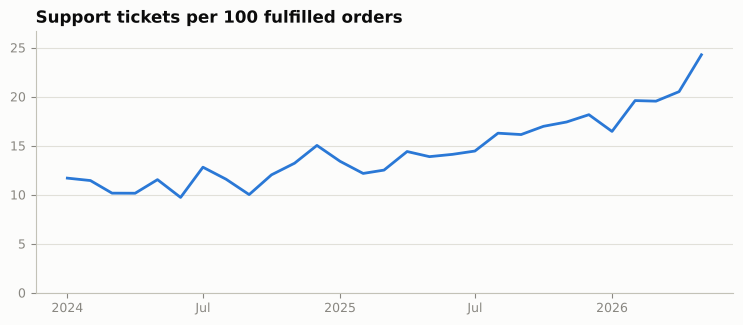

First month: 11.7; last month: 24.3


In [31]:
load = business["monthly_support"]
fig, ax = plt.subplots(figsize=(9, 3.4))
plotting.line_chart(load, "month", "tickets_per_100_orders", "Support tickets per 100 fulfilled orders", ax=ax)
plt.show()
print(f"First month: {load['tickets_per_100_orders'].iloc[0]:.1f}; last month: {load['tickets_per_100_orders'].iloc[-1]:.1f}")

**Result.**
- Tickets per 100 fulfilled orders roughly **doubled** over the period, so support demand is growing faster than sales.
- CSAT is high on average, but the share of satisfied customers drops from about 97% for tickets resolved in under 8 hours to about 63% beyond 48 hours.
- Low-priority tickets take the longest to resolve.

**Implication.** Support capacity and triage need to keep pace with growth. The link between resolution time and satisfaction is an association, not proof of cause, but it is strong enough to justify a service-level target (for example, no ticket open longer than 48 hours).

## 11. Repeat purchase and retention

In [32]:
display(business["purchase_frequency"])
print(f"Repeat-purchase rate (2+ completed orders among buyers): {business['repeat_purchase_rate_pct']:.1f}%")

,completed_orders,customers,share_pct
0,0,317,5.28
1,1,685,11.42
2,2,842,14.03
3,3-4,1579,26.32
4,5-9,1964,32.73
5,10+,613,10.22


Repeat-purchase rate (2+ completed orders among buyers): 87.9%


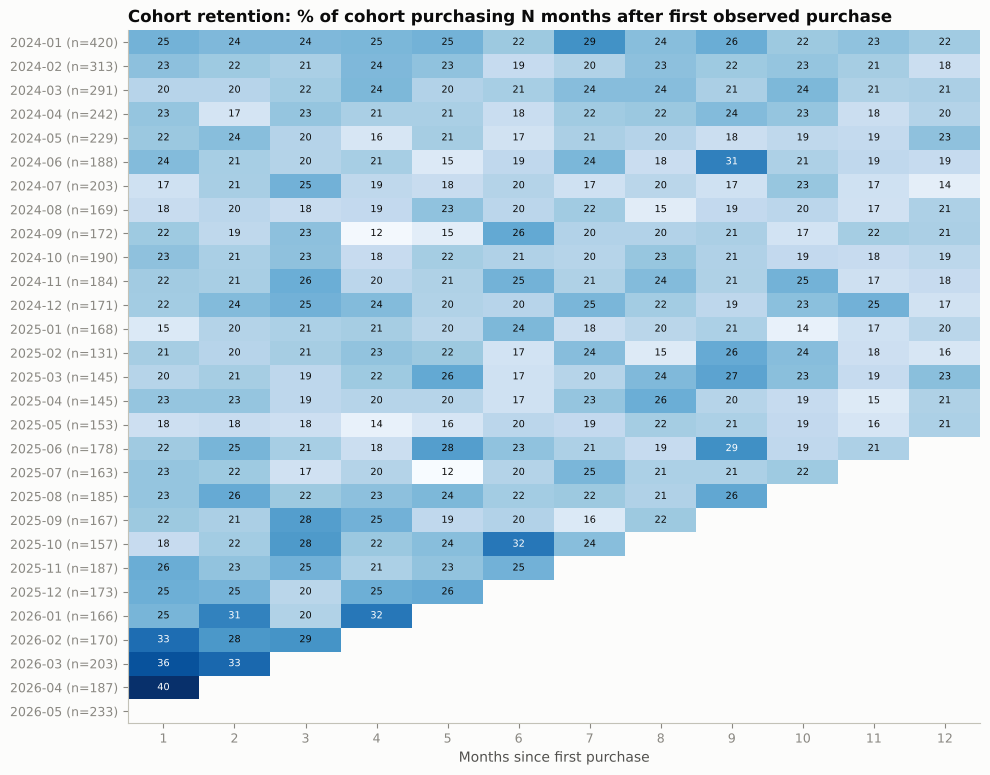

In [33]:
retention = business["cohort_retention"]
matrix = retention.drop(columns=["cohort_size", 0])
matrix.index = [f"{d:%Y-%m} (n={n})" for d, n in zip(retention.index, retention["cohort_size"])]
fig, ax = plt.subplots(figsize=(11, 9))
plotting.heatmap(matrix, "Cohort retention: % of cohort purchasing N months after first observed purchase", ax=ax, xlabel="Months since first purchase")
plt.show()

In [34]:
curve = metrics.average_retention_curve(retention)
display(curve.T)
m1 = retention[1]
recent = m1[m1.index >= "2025-12-01"].dropna()
older = m1[m1.index < "2025-12-01"].dropna()
print(f"Average month-1 retention: cohorts Dec 2025+ {recent.mean():.1f}% vs earlier cohorts {older.mean():.1f}%")

,0,1,2,3,4,5,6,7,8,9,10,11,12
months_since_first,0.00,1.00,2.00,3.00,4.00,5.00,6.00,7.00,8.00,9.00,10.00,11.00,12.00
retention_pct,100.00,23.39,22.69,22.39,21.49,21.25,21.05,22.00,21.37,22.57,21.19,19.50,19.81
cohorts_observed,29.00,28.00,27.00,26.00,25.00,24.00,23.00,22.00,21.00,20.00,19.00,18.00,17.00


Average month-1 retention: cohorts Dec 2025+ 31.7% vs earlier cohorts 21.4%


**Result.**
- Most buyers purchase repeatedly over the whole period, but in any given month only about one in five customers from a cohort buys again. The average retention curve **declines only slightly**, from about 23% in month 1 to about 20% in month 12.
- Cohorts from December 2025 onward show **higher month-1 retention** (about 32% against about 21% for earlier cohorts). This is a promising signal, but it rests on small cohorts (about 170–230 customers) and few observed months.
- 2024 cohorts are left-censored: they include 2023 sign-ups whose earlier purchases are not in the data.

**Implication.** Retention is steady, so churn risk is better judged by each customer's recency and frequency than by tenure. Notebook 02 models exactly this.

## 12. Summary and follow-up questions

**Evidence-based findings (synthetic data)**
1. Growth is volume-driven: more buyers, flat AOV and stable margin.
2. Marketing spend exceeds product-level profit, and paid channels cost about 11× first-year profit per new customer. Customer quality is similar across channels.
3. Deeper discounts cut margin sharply without a significant effect on refunds.
4. Support load per order has doubled. Satisfaction falls sharply for slow tickets.
5. Retention is steady at about 20–23% of a cohort buying in any later month. Recent cohorts look stronger.

**Follow-up questions for the business**
- What would a holdout test that cuts paid social or search spend show about incremental customers?
- Do discounts create incremental orders, or do they subsidise purchases that would have happened anyway?
- Why are tickets per order rising? Delivery partner, product mix or a new channel? Linking tickets to orders would answer this.
- Which actions explain the stronger late-2025 cohorts, and can they be repeated?
- What are the shipping, fulfilment and support costs needed to compute true contribution margin and CLV?

Recommendations are written up in `reports/business_recommendations.md`.